# Cas 3D

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": "Computer Modern",
})

a, b, c, d = -26, 285.67,-202.33, 16741000

e, f, g, h = 0.5, 3.33, 0.33, 350000

x = np.linspace(0, 400000, 2000)
y = np.linspace(0, 100000, 2000)
X, Y = np.meshgrid(x, y)

Z_plane = (d - a*X - b*Y) / c

mask = ((e*X + f*Y + g*Z_plane) <= h) & (Z_plane>=0)
Z_valid = np.where(mask, Z_plane, np.nan)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(projection='3d')

surf = ax.plot_surface(X, Y, Z_valid, alpha=0.7, cmap='viridis')
ax.plot_wiref_keyrame(X, Y, Z_plane, alpha=0.2, color='gray',
                  rstride=10, cstride=10,linewidth=0.5
                  )

ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$y$')
ax.set_zlabel(r'$z$')

ax.set_zlim(0,np.max(Z_plane))

title = rf'${a}x + {b}y + {c}z = {d}, \quad {e}x + {f}y + {g}z \leq {h}$'
ax.set_title(title)

fig = plt.gcf()
fig.set_constrained_layout(True)

plt.show()


# Cas 2D

In [1]:
import bw2data as bd
import bw2calc as bc
from tqdm import tqdm
import polars as pl
from archetypes_re2020.data.remove_extreme_outliers import outliers

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

10:42:43+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [3]:
arch_db = bd.Database("2026-8-13-16h52_archetypes_RE2020_BB")
dict_w = {}

for a in tqdm(arch_db) :
    phi = list(a.production())[0]["amount"]
    tmp = {e["input"][1] : e["amount"]/phi for e in tqdm(a.technosphere(),leave = False)}
    dict_w = dict_w | tmp

100%|██████████| 5/5 [00:01<00:00,  3.55it/s]


In [4]:

Hb_gwp= pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Hb/260810-Hb/scores_climate change_global warming potential (GWP100)_1000.parquet")
Hb_aware = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Hb/260810-Hb/scores_water use_user deprivation potential (deprivation-weighted water consumption)_1000.parquet")

In [5]:
score_open_space = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-8-25-23h5_MC_runs/scores.parquet")

In [6]:
score_open_space

iteration,demand,indicator,score
u32,str,str,f64
0,"""roads_m2_per""","""ecoinvent-3.11 | EF v3.1 | aci…",16.498576
1,"""roads_m2_per""","""ecoinvent-3.11 | EF v3.1 | aci…",25.597498
2,"""roads_m2_per""","""ecoinvent-3.11 | EF v3.1 | aci…",18.375509
3,"""roads_m2_per""","""ecoinvent-3.11 | EF v3.1 | aci…",20.630411
4,"""roads_m2_per""","""ecoinvent-3.11 | EF v3.1 | aci…",13.369354
…,…,…,…
995,"""vegetation_m2_per""","""ecoinvent-3.11 | EF v3.1 | wat…",0.039808
996,"""vegetation_m2_per""","""ecoinvent-3.11 | EF v3.1 | wat…",0.038779
997,"""vegetation_m2_per""","""ecoinvent-3.11 | EF v3.1 | wat…",0.038384


In [7]:
Hb_gwp = Hb_gwp.with_columns(
    poids = pl.col("batiment").replace_strict(dict_w, default = 0.,return_dtype = pl.Float64)
).drop_nulls("usage")
Hb_aware = Hb_aware.with_columns(
    poids = pl.col("batiment").replace_strict(dict_w, default = 0.,return_dtype = pl.Float64)
).drop_nulls("usage")

dict_Hbs = {"gwp" : Hb_gwp,"aware" : Hb_aware}

In [8]:
import numpy as np


def weighted_median(values, weights):
    
    return np.quantile(values, q = 0.5, weights = weights,method="inverted_cdf")


usages = ["Logement collectif","Bureau"]

res_dict = {ind : {u : {"mu" : 0, "med" : 0, "std" : 0 } for u in usages} for ind in dict_Hbs.keys()}

for ind, Hb in dict_Hbs.items() :
    for usage in res_dict[ind].keys() :
        Hb_filtered = Hb.filter(pl.col("usage") == usage)

        scores = Hb_filtered["score"].to_numpy()
        poids = Hb_filtered["poids"].to_numpy()

        # Weighted mean
        w_mean = np.average(scores, weights=poids)

        w_var = np.average((scores - w_mean) ** 2, weights=poids)
        w_std = np.sqrt(w_var)


        w_median = weighted_median(scores, poids)
        res_dict[ind][usage]["mu"] = w_mean
        res_dict[ind][usage]["med"] = w_median
        res_dict[ind][usage]["std"] = w_std

In [9]:
# On ajoute les stats des EP, av
route = score_open_space.filter(pl.col("demand")=="roads_m2_per")
vege = score_open_space.filter(pl.col("demand")=="vegetation_m2_per")
route_gwp = route.filter(pl.col("indicator").str.contains("GWP100"))["score"]
route_aware = route.filter(pl.col("indicator").str.contains("water"))["score"]
vege_gwp = vege.filter(pl.col("indicator").str.contains("GWP100"))["score"]
vege_aware = vege.filter(pl.col("indicator").str.contains("water"))["score"]
res_dict["gwp"]["route"] = {'mu': route_gwp.mean(), 'med': route_gwp.median(), 'std': route_gwp.std()}
res_dict["aware"]["route"] = {'mu': route_aware.mean(), 'med': route_aware.median(), 'std': route_aware.std()}
res_dict["gwp"]["vegetation"] = {'mu': vege_gwp.mean(), 'med': vege_gwp.median(), 'std': vege_gwp.std()}
res_dict["aware"]["vegetation"] = {'mu': vege_aware.mean(), 'med': vege_aware.median(), 'std': vege_aware.std()}


In [10]:
res_dict

{'gwp': {'Logement collectif': {'mu': np.float64(1376.2723714786014),
   'med': array(1290.2343, dtype=float32),
   'std': np.float64(809.849419466249)},
  'Bureau': {'mu': np.float64(1274.4276136726598),
   'med': array(1071.2778, dtype=float32),
   'std': np.float64(1593.4688855660522)},
  'route': {'mu': 1545.7484830995697,
   'med': 890.3098036394509,
   'std': 1601.9248046537898},
  'vegetation': {'mu': 0.04697966856333012,
   'med': 0.0345466777498448,
   'std': 0.04746416060412812}},
 'aware': {'Logement collectif': {'mu': np.float64(728.5950015917698),
   'med': array(698.3326, dtype=float32),
   'std': np.float64(268.1492267257458)},
  'Bureau': {'mu': np.float64(893.8878959696137),
   'med': array(757.46387, dtype=float32),
   'std': np.float64(1755.8618842576932)},
  'route': {'mu': 50953.61431650816,
   'med': 993.0373061727748,
   'std': 500044.527424463},
  'vegetation': {'mu': 0.056706848626378925,
   'med': 0.010212499406749967,
   'std': 3.381325147212415}}}

In [2]:
def emprise_projet(Slc,Sbur,param_dict) :
    a = (1/param_dict["Rlc"])+(param_dict["Eep_lc"]/param_dict["Rep"])+(param_dict["Eequip_lc"]/param_dict["Requip"])
    b= (1/param_dict["Rbur"])+(param_dict["Eep_bur"]/param_dict["Rep"])+(param_dict["Eequip_bur"]/param_dict["Requip"])
    return a*Slc + b*Sbur

def cout_projet(Slc,Sbur,param_dict):
    a= (
        param_dict["Ksol"]*(
            (1/param_dict["Rlc"])
            +param_dict["Eep_lc"]/param_dict["Rep"]
            +(param_dict["Eequip_lc"]/param_dict["Requip"])
            ) 
            + param_dict["Eep_lc"]*param_dict["Cep"]
            +param_dict["Eequip_lc"]*param_dict["Cequip"]
            -param_dict["Klc"]
    )
    b= (
        param_dict["Ksol"]*(
            (1/param_dict["Rbur"])
            +param_dict["Eep_bur"]/param_dict["Rep"]
            +(param_dict["Eequip_bur"]/param_dict["Requip"])
            ) 
            + param_dict["Eep_bur"]*param_dict["Cep"]
            +param_dict["Eequip_bur"]*param_dict["Cequip"]
            -param_dict["Kbur"]
    )

    return a*Slc+b*Sbur

def impact_projet(Slc,Sbur,param_dict,res_dict,ind="gwp",stat = "mu") :
    part_route = param_dict["part_route"]
    imp_EP = (
        res_dict[ind]["vegetation"][stat]*(1-part_route) 
        + res_dict[ind]["route"][stat]*part_route
        )
    a= (
    param_dict["Ksol"]*(
        (1/param_dict["Rlc"])
        +param_dict["Eep_lc"]/param_dict["Rep"]
        +(param_dict["Eequip_lc"]/param_dict["Requip"])
        ) 
        + param_dict["Eep_lc"]*param_dict["Cep"]
        +param_dict["Eequip_lc"]*param_dict["Cequip"]
        -param_dict["Klc"]
    )
    b= (
        param_dict["Ksol"]*(
            (1/param_dict["Rbur"])
            +param_dict["Eep_bur"]/param_dict["Rep"]
            +(param_dict["Eequip_bur"]/param_dict["Requip"])
            ) 
            + param_dict["Eep_bur"]*param_dict["Cep"]
            +param_dict["Eequip_bur"]*param_dict["Cequip"]
            -param_dict["Kbur"]
    )

    a = (
        res_dict[ind]["Logement collectif"][stat] 
        + param_dict["Eequip_lc"]*res_dict[ind]["Bureau"][stat] 
        + param_dict["Eep_lc"]*imp_EP
    )
    b = (
        res_dict[ind]["Bureau"][stat] 
        + param_dict["Eequip_bur"]*res_dict[ind]["Bureau"][stat] 
        + param_dict["Eep_bur"]*imp_EP
    )

    return a*Slc + b*Sbur

In [22]:
param_amenageur = {
    "Ksol" : 349, # prix du m2 sol en euros
    "Klc" : 332, # charge foncière logement collectif en euros/m2SDP
    "Kbur" : 239, # charge foncière bureau en euros/m2SDP
    "Cep" : 350, # cout de construction espace public en euros/m2
    "Cequip" : 2500, # cout de construction équipement public en euros/m2SDP
    "Eep_lc" : 0.36, # ratio de m2 d'espace public par m2 de logements
    "Eequip_lc" : 0.05, # ratio de m2 d'équipement public par m2 de logements
    "Eep_bur" : 0.1, # ratio de m2 d'espace public par m2 de logements
    "Eequip_bur" : 0, # ratio de m2 d'équipement public par m2 de logements
    "Rlc" : 3, # m2SDP par m2 emprise au sol logement collectif
    "Rbur" : 5, # m2SDP par m2 emprise au sol bureau
    "Rep" : 1, # m2 par m2 emprise au sol esapce public
    "Requip" : 3, # m2SDP par m2 emprise au sol équipement public
    "aire_projet" : 350000,
    "subvention": 16741000,
    "part_route" : 0.5 # part des voiries dans l'espace public
}


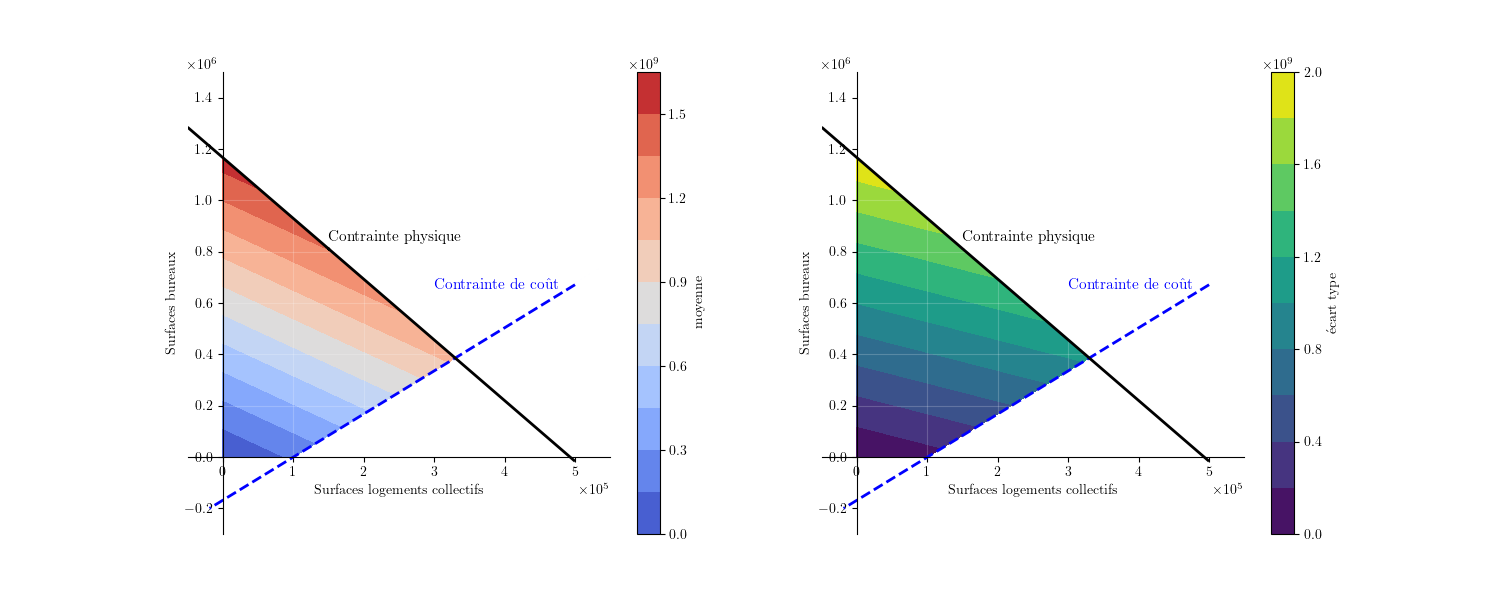

In [43]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": "Computer Modern",
})

x_annot_cout = 280000
y_annot_cout = 760000

x_annot_emp = 130000
y_annot_emp = 950000

N = 2000
x = np.linspace(-5E4, 5E5, N)
y = np.linspace(-2E5, 1.5E6, N)
X, Y = np.meshgrid(x, y)

cout = lambda x,y : cout_projet(x,y,param_amenageur)
emprise = lambda x,y : emprise_projet(x,y,param_amenageur)

mask = (
    (cout(X,Y) <= param_amenageur["subvention"])
    & (emprise(X,Y) <= param_amenageur["aire_projet"])
    & (X>=0) & (Y>=0)
    )

ind = "gwp"

impact = lambda x, y: impact_projet(x, y,param_amenageur,res_dict,ind,stat="mu")
Z = impact(X, Y)
Z_masked = np.where(mask, Z, np.nan)

impact_std = lambda x, y: impact_projet(x, y,param_amenageur,res_dict,ind,stat="std")
Z_std = impact_std(X, Y)
Z_masked_std = np.where(mask, Z_std, np.nan)


fill = lambda x,y : 0
Z_fill = fill(X,Y)
Z_fill_masked = np.where(mask, Z_fill, np.nan)

fig, axs = plt.subplots(1,2,figsize=(15, 6))

surf = axs[0].contourf(X, Y, Z_masked, levels=10, cmap='coolwarm')
cbar = fig.colorbar(surf, ax=axs[0], label='moyenne')



surf_std = axs[1].contourf(X, Y, Z_masked_std, levels=10, cmap='viridis')
cbar_std = fig.colorbar(surf_std, ax=axs[1], label='écart type')



# # pour juste remplir
# surf = ax.contourf(X, Y, Z_fill_masked, levels=100, cmap='coolwarm')

for ax in axs :
    ax.contour(X, Y, cout_projet(X, Y, param_amenageur),
                levels=[param_amenageur["subvention"]], colors='blue', linewidths=2, linestyles='--')
    ax.contour(X, Y, emprise_projet(X, Y, param_amenageur),
                levels=[param_amenageur["aire_projet"]], colors='black', linewidths=2, linestyles='-')


    ax.annotate(f'Contrainte de coût',
                xy=(x_annot_cout, y_annot_cout), fontsize=11, color='blue',
                xytext=(10, -20), textcoords='offset points')


    ax.annotate(f'Contrainte physique',
                xy=(x_annot_emp, y_annot_emp), fontsize=11, color='black',
                xytext=(10, -20), textcoords='offset points')


    ax.set_xlabel('Surfaces logements collectifs')
    ax.set_ylabel('Surfaces bureaux')

    ax.grid(True, alpha=0.2, color='white')


    ax.set_xlim(-50000,550000)
    ax.set_ylim(-300000,1500000)

    ax.spines['left'].set_position('zero')
    ax.spines['bottom'].set_position('zero')

    ax.spines['right'].set_color('none')
    ax.spines['top'].set_color('none')

    from matplotlib.ticker import ScalarFormatter

    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-3, 3))
    ax.xaxis.set_major_formatter(formatter)
    ax.yaxis.set_major_formatter(formatter)

plt.savefig("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Pb_amenageur/pb_amenageur_gwp.pdf",dpi=300,bbox_inches = "tight")

# plt.tight_layout()
# plt.show()

In [ ]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, Layout

xlim = 1000000
ylim = 1000000
stat = "mu"
ind = "aware"

N = 500
x = np.linspace(0, xlim, N)
y = np.linspace(0, ylim, N)
X, Y = np.meshgrid(x, y)

impact = lambda x, y: impact_projet(x, y,param_amenageur,res_dict,ind,stat=stat)


slider_layout = Layout(width='400px')

sliders = {
    "subvention":  FloatSlider(value=16741000, min=0,   max=50_000_000, step=500_000, description='Subvention',  layout=slider_layout, readout_format=',.0f'),
    "aire_projet": FloatSlider(value=350000,   min=0,   max=2_000_000,  step=10_000,  description='Aire projet',  layout=slider_layout, readout_format=',.0f'),
    "Ksol":        FloatSlider(value=110,      min=0,   max=1000,      step=10,       description='Ksol (€/m²)', layout=slider_layout),
    "Klc":         FloatSlider(value=332,      min=0,   max=1000,       step=5,       description='Klc (€/m²)',  layout=slider_layout),
    "Kbur":        FloatSlider(value=239,      min=0,   max=1000,       step=5,       description='Kbur (€/m²)', layout=slider_layout),
    "Cep":         FloatSlider(value=350,      min=0,   max=2000,       step=50,      description='Cep (€/m²)',  layout=slider_layout),
    "Cequip":      FloatSlider(value=2500,     min=0,   max=5000,       step=50,      description='Cequip',       layout=slider_layout),
    "Eep_lc":         FloatSlider(value=0.36,     min=0,   max=1,          step=0.01,    description='Eep_lc',          layout=slider_layout),
    "Eequip_lc":      FloatSlider(value=0.05,     min=0,   max=1,          step=0.01,    description='Eequip_lc',       layout=slider_layout),
    "Eep_bur":         FloatSlider(value=0.1,     min=0,   max=1,          step=0.01,    description='Eep_bur',          layout=slider_layout),
    "Eequip_bur":      FloatSlider(value=0.05,     min=0,   max=1,          step=0.01,    description='Eequip_bur',       layout=slider_layout),
    "Rlc":         FloatSlider(value=2,        min=0.5, max=10,         step=0.1,     description='Rlc',          layout=slider_layout),
    "Rbur":        FloatSlider(value=3,        min=0.5, max=10,         step=0.1,     description='Rbur',         layout=slider_layout),
}

@interact(**sliders)
def interactive_plot(**kwargs):
    p = {**param_amenageur, **kwargs}

    mask = (cout_projet(X, Y, p) <= p["subvention"]) & \
           (emprise_projet(X, Y, p) <= p["aire_projet"])
    
    Z = impact(X, Y)
    Z_masked = np.where(mask, Z, np.nan)

    # Fresh figure every time — no colorbar removal issues
    fig, ax = plt.subplots(figsize=(10, 8))

    if np.all(np.isnan(Z_masked)):
        ax.text(0.5, 0.5, 'Aucune zone faisable', transform=ax.transAxes,
                ha='center', va='center', fontsize=16, color='red')
    else:
        vmin, vmax = np.nanmin(Z_masked), np.nanmax(Z_masked)
        levels = np.linspace(vmin, vmax, 100)
        surf = ax.contourf(X, Y, Z_masked, levels=levels, cmap='coolwarm', extend='neither')

        ax.contour(X, Y, cout_projet(X, Y, p),
                   levels=[p["subvention"]], colors='blue', linewidths=2, linestyles='--')
        ax.contour(X, Y, emprise_projet(X, Y, p),
                   levels=[p["aire_projet"]], colors='black', linewidths=2, linestyles='-')

        # --- Slope annotations ---
        # cout_projet coefficients

        a_cout = (p["Ksol"]*(
            (1/p["Rlc"])
            +p["Eep_lc"]/p["Rep"]
            +(p["Eequip_lc"]/p["Requip"])
            ) 
            + p["Eep_lc"]*p["Cep"]
            +p["Eequip_lc"]*p["Cequip"]
            -p["Klc"]
        )
        b_cout = (
        p["Ksol"]*(
            (1/p["Rbur"])
            +p["Eep_bur"]/p["Rep"]
            +(p["Eequip_bur"]/p["Requip"])
            ) 
            + p["Eep_bur"]*p["Cep"]
            +p["Eequip_bur"]*p["Cequip"]
            -p["Kbur"]
        )
        slope_cout = -a_cout / b_cout if b_cout != 0 else np.inf

        # emprise_projet coefficients
        a_emp = (1/p["Rlc"])+(p["Eep_lc"]/p["Rep"])+(p["Eequip_lc"]/p["Requip"])
        b_emp= (1/p["Rbur"])+(p["Eep_bur"]/p["Rep"])+(p["Eequip_bur"]/p["Requip"])
        slope_emp = -a_emp / b_emp if b_emp != 0 else np.inf

        # Find a point on each line within the plot to place the annotation
        # Line: a*x + b*y = c → y = (c - a*x) / b
        mid_x = xlim/2  # middle of x-range

        if b_cout != 0:
            y_cout = (p["subvention"] - a_cout * mid_x) / b_cout
            if 0 <= y_cout <= xlim:
                ax.annotate(f'Coût: pente = {slope_cout:.1f}',
                            xy=(mid_x, y_cout), fontsize=14, color='blue',
                            xytext=(10, -20), textcoords='offset points')

        if b_emp != 0:
            y_emp = (p["aire_projet"] - a_emp * mid_x/3) / b_emp
            if 0 <= y_emp <= ylim:
                ax.annotate(f'Emprise : pente = {slope_emp:.1f}',
                            xy=(mid_x/3, y_emp), fontsize=14, color='black',
                            xytext=(20, -20), textcoords='offset points')

        fig.colorbar(surf, ax=ax, label='Impact')

    ax.set_xlabel('Surfaces logements collectifs (m²)')
    ax.set_ylabel('Surfaces bureaux (m²)')
    ax.set_xlim(0, xlim)
    ax.set_ylim(0, ylim)
    ax.grid(True, alpha=0.2, color='white')

    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=16741000.0, description='Subvention', layout=Layout(width='400px'), ma…

## filtre selon R

In [12]:
bat = pl.read_csv("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/raw/202505_export_batiments_daact.csv",ignore_errors=True)
bat = bat.with_columns(
    R=pl.col("sref") / pl.col("emprise_au_sol"),
    bat_id=pl.concat_str(
        [pl.col("projet_id"), pl.col("batiment_index")],
        separator="_",
    ),
)


In [13]:
to_keep = bat.filter(
    ((pl.col("usage_principal_1_txt") == "Logement collectif") & (pl.col("R")>=4.3))
    | ((pl.col("usage_principal_1_txt") == "Bureau") & (pl.col("R")>=1.95))
    )["bat_id"].to_list()

In [14]:
dict_Hbs_filtered = {}
for k,v in dict_Hbs.items() :
    dict_Hbs_filtered[k] = v.filter(pl.col("batiment").is_in(to_keep))

In [15]:
import numpy as np


def weighted_median(values, weights):
    
    return np.quantile(values, q = 0.5, weights = weights,method="inverted_cdf")


usages = ["Logement collectif","Bureau"]

res_dict_filtered = {ind : {u : {"mu" : 0, "med" : 0, "std" : 0 } for u in usages} for ind in dict_Hbs_filtered.keys()}

for ind, Hb in dict_Hbs_filtered.items() :
    for usage in res_dict[ind].keys() :
        Hb_filtered = Hb.filter(pl.col("usage") == usage)

        scores = Hb_filtered["score"].to_numpy()
        poids = Hb_filtered["poids"].to_numpy()

        # Weighted mean
        w_mean = np.average(scores, weights=poids)

        w_var = np.average((scores - w_mean) ** 2, weights=poids)
        w_std = np.sqrt(w_var)


        w_median = weighted_median(scores, poids)
        res_dict_filtered[ind][usage]["mu"] = w_mean
        res_dict_filtered[ind][usage]["med"] = w_median
        res_dict_filtered[ind][usage]["std"] = w_std

In [16]:
res_dict_filtered

{'gwp': {'Logement collectif': {'mu': np.float64(1382.0122807546968),
   'med': array(1181.7062, dtype=float32),
   'std': np.float64(1208.3476486730542)},
  'Bureau': {'mu': np.float64(1007.7384143122722),
   'med': array(891.0715, dtype=float32),
   'std': np.float64(918.9594394736191)}},
 'aware': {'Logement collectif': {'mu': np.float64(730.3860269354036),
   'med': array(659.9016, dtype=float32),
   'std': np.float64(418.5303760236568)},
  'Bureau': {'mu': np.float64(733.9228843942877),
   'med': array(691.08264, dtype=float32),
   'std': np.float64(352.9713071591339)}}}

In [17]:
res_dict

{'gwp': {'Logement collectif': {'mu': np.float64(1376.2723714786014),
   'med': array(1290.2343, dtype=float32),
   'std': np.float64(809.849419466249)},
  'Bureau': {'mu': np.float64(1274.4276136726598),
   'med': array(1071.2778, dtype=float32),
   'std': np.float64(1593.4688855660522)}},
 'aware': {'Logement collectif': {'mu': np.float64(728.5950015917698),
   'med': array(698.3326, dtype=float32),
   'std': np.float64(268.1492267257458)},
  'Bureau': {'mu': np.float64(893.8878959696137),
   'med': array(757.46387, dtype=float32),
   'std': np.float64(1755.8618842576932)}}}

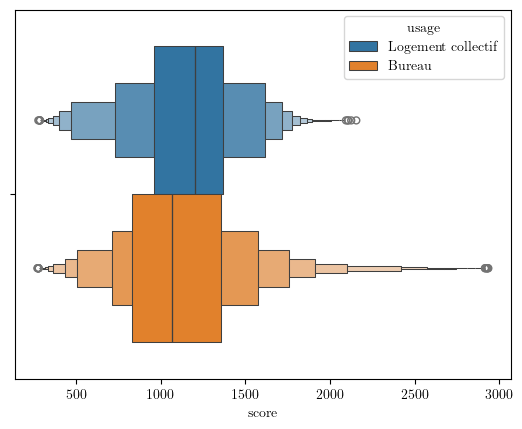

In [18]:
%matplotlib inline
plt.close('all')
import seaborn as sns

sns.boxenplot(data = outliers(dict_Hbs_filtered["gwp"],"score").filter(~pl.col("score_extreme_outliers")),x = "score",hue = "usage")
plt.show()

In [19]:
to_graph = outliers(dict_Hbs_filtered["gwp"],"score").filter(~pl.col("score_extreme_outliers"))

In [20]:
to_graph["usage"].value_counts()

usage,count
cat,u32
"""Bureau""",105973
"""Logement collectif""",72000


In [21]:
dict_Hbs_filtered["gwp"]["usage"].value_counts()

usage,count
cat,u32
"""Logement collectif""",76000
"""Bureau""",107000


In [22]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, Layout

xlim = 1000000
ylim = 1000000
stat = "mu"
ind = "gwp"

N = 500
x = np.linspace(0, xlim, N)
y = np.linspace(0, ylim, N)
X, Y = np.meshgrid(x, y)

impact = lambda x, y: impact_projet(x, y,param_amenageur,res_dict_filtered,ind,stat=stat)


slider_layout = Layout(width='400px')

sliders = {
    "subvention":  FloatSlider(value=16741000, min=0,   max=50_000_000, step=500_000, description='Subvention',  layout=slider_layout, readout_format=',.0f'),
    "aire_projet": FloatSlider(value=350000,   min=0,   max=2_000_000,  step=10_000,  description='Aire projet',  layout=slider_layout, readout_format=',.0f'),
    "Ksol":        FloatSlider(value=110,      min=0,   max=1000,      step=10,       description='Ksol (€/m²)', layout=slider_layout),
    "Klc":         FloatSlider(value=332,      min=0,   max=1000,       step=5,       description='Klc (€/m²)',  layout=slider_layout),
    "Kbur":        FloatSlider(value=239,      min=0,   max=1000,       step=5,       description='Kbur (€/m²)', layout=slider_layout),
    "Cep":         FloatSlider(value=350,      min=0,   max=2000,       step=50,      description='Cep (€/m²)',  layout=slider_layout),
    "Cequip":      FloatSlider(value=2500,     min=0,   max=5000,       step=50,      description='Cequip',       layout=slider_layout),
    "Eep":         FloatSlider(value=0.36,     min=0,   max=2,          step=0.01,    description='Eep',          layout=slider_layout),
    "Eequip":      FloatSlider(value=0.05,     min=0,   max=1,          step=0.01,    description='Eequip',       layout=slider_layout),
    "Rlc":         FloatSlider(value=4.3,        min=0.5, max=10,         step=0.1,     description='Rlc',          layout=slider_layout),
    "Rbur":        FloatSlider(value=1.95,        min=0.5, max=10,         step=0.1,     description='Rbur',         layout=slider_layout),
}

@interact(**sliders)
def interactive_plot(**kwargs):
    p = {**param_amenageur, **kwargs}

    mask = (cout_projet(X, Y, p) <= p["subvention"]) & \
           (emprise_projet(X, Y, p) <= p["aire_projet"])
    
    Z = impact(X, Y)
    Z_masked = np.where(mask, Z, np.nan)

    # Fresh figure every time — no colorbar removal issues
    fig, ax = plt.subplots(figsize=(10, 8))

    if np.all(np.isnan(Z_masked)):
        ax.text(0.5, 0.5, 'Aucune zone faisable', transform=ax.transAxes,
                ha='center', va='center', fontsize=16, color='red')
    else:
        vmin, vmax = np.nanmin(Z_masked), np.nanmax(Z_masked)
        levels = np.linspace(vmin, vmax, 100)
        surf = ax.contourf(X, Y, Z_masked, levels=levels, cmap='coolwarm', extend='neither')

        ax.contour(X, Y, cout_projet(X, Y, p),
                   levels=[p["subvention"]], colors='blue', linewidths=2, linestyles='--')
        ax.contour(X, Y, emprise_projet(X, Y, p),
                   levels=[p["aire_projet"]], colors='black', linewidths=2, linestyles='-')

        # --- Slope annotations ---
        # cout_projet coefficients
        a_cout = p["Eep"]*p["Cep"] + p["Eequip"]*p["Cequip"] + p["Ksol"]/p["Rlc"] - p["Klc"]
        b_cout = p["Ksol"]/p["Rbur"] - p["Kbur"]
        slope_cout = -a_cout / b_cout if b_cout != 0 else np.inf

        # emprise_projet coefficients
        a_emp = 1/p["Rlc"] + p["Eep"]/p["Rep"] + p["Eequip"]/p["Requip"]
        b_emp = 1/p["Rbur"]
        slope_emp = -a_emp / b_emp if b_emp != 0 else np.inf

        # Find a point on each line within the plot to place the annotation
        # Line: a*x + b*y = c → y = (c - a*x) / b
        mid_x = xlim/2  # middle of x-range

        if b_cout != 0:
            y_cout = (p["subvention"] - a_cout * mid_x) / b_cout
            if 0 <= y_cout <= xlim:
                ax.annotate(f'Coût: pente = {slope_cout:.3f}',
                            xy=(mid_x, y_cout), fontsize=14, color='blue',
                            xytext=(10, -20), textcoords='offset points')

        if b_emp != 0:
            y_emp = (p["aire_projet"] - a_emp * mid_x/3) / b_emp
            if 0 <= y_emp <= ylim:
                ax.annotate(f'Emprise : pente = {slope_emp:.1f}',
                            xy=(mid_x/3, y_emp), fontsize=14, color='black',
                            xytext=(20, -20), textcoords='offset points')

        fig.colorbar(surf, ax=ax, label='Impact')

    ax.set_xlabel('Surfaces logements collectifs (m²)')
    ax.set_ylabel('Surfaces bureaux (m²)')
    ax.set_xlim(0, xlim)
    ax.set_ylim(0, ylim)
    ax.grid(True, alpha=0.2, color='white')

    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=16741000.0, description='Subvention', layout=Layout(width='400px'), ma…

# Tracé discernabilité

In [3]:
param_amenageur = {
    "Ksol" : 349, # prix du m2 sol en euros
    "Klc" : 332, # charge foncière logement collectif en euros/m2SDP
    "Kbur" : 239, # charge foncière bureau en euros/m2SDP
    "Cep" : 350, # cout de construction espace public en euros/m2
    "Cequip" : 2500, # cout de construction équipement public en euros/m2SDP
    "Eep_lc" : 0.36, # ratio de m2 d'espace public par m2 de logements
    "Eequip_lc" : 0.05, # ratio de m2 d'équipement public par m2 de logements
    "Eep_bur" : 0.1, # ratio de m2 d'espace public par m2 de bureaux
    "Eequip_bur" : 0, # ratio de m2 d'équipement public par m2 de bureaux
    "Rlc" : 3, # m2SDP par m2 emprise au sol logement collectif
    "Rbur" : 5, # m2SDP par m2 emprise au sol bureau
    "Rep" : 1, # m2 par m2 emprise au sol esapce public
    "Requip" : 3, # m2SDP par m2 emprise au sol équipement public
    "aire_projet" : 350000,
    "subvention": 16741000,
    "part_route" : 0.5 # part des voiries dans l'espace public
}


In [4]:
map_arch = {
    "individual_housing" : "Maison individuelle ou accolée",
    "collective_housing" : "Logement collectif",
    "office_building" : "Bureau",
    # "industrial_building" : "Bureau",
    # "education_building" : 'Enseignement secondaire (partie jour)',
    "education_building" : "Bureau",
    "roads" : "roads_m2_per",
    "vegetation" : "vegetation_m2_per"}


Création et échantillonage de l'espace de conception

In [5]:
import numpy as np
N = 100
x = np.linspace(0, 5E5, N)
y = np.linspace(0, 1.5E6, N)
X, Y = np.meshgrid(x, y)

cout = lambda x,y : cout_projet(x,y,param_amenageur)
emprise = lambda x,y : emprise_projet(x,y,param_amenageur)

mask = (
    (cout(X,Y) <= param_amenageur["subvention"])
    & (emprise(X,Y) <= param_amenageur["aire_projet"])
    & (X>=0) & (Y>=0) & (X+Y >0)
    )
X_valid = X[mask]
Y_valid = Y[mask]
pairs = np.column_stack((X_valid,Y_valid)) # On a discrètiser l'espace de conception

In [6]:
len(pairs)

2816

In [7]:
def f_tilde(s_lc,s_bur,param_amenageur):
    
    s_ep = param_amenageur["Eep_lc"]*s_lc + param_amenageur["Eep_bur"]*s_bur
    s_route = 0.1*(s_bur + s_lc)
    s_vege = s_ep-s_route
    return  {
        "individual_housing" : 0,
        "collective_housing" : s_lc,
        "office_building" : s_bur,
        "education_building" : param_amenageur["Eequip_bur"]*s_bur + param_amenageur["Eequip_lc"]*s_lc ,
        "roads" : s_route,
        "vegetation" : s_vege,
        }

 On import fonctions de compare_pu.py à la main pour modif éventuel

In [8]:
from archetypes_re2020.config import PROCESSED_DATA_DIR
from archetypes_re2020.data.remove_extreme_outliers import outliers

def build_Hb_filtered(parquet_file,dict_w):
    tmp = pl.read_parquet(parquet_file)
    tmp = tmp.with_columns(
        poids = pl.col("batiment").replace_strict(dict_w, default = 0.,return_dtype = pl.Float64)
    ).drop_nulls("usage")

    # valeurs aberrantes par usage
    parts = tmp.partition_by('usage')
    tmp = pl.concat([outliers(part, "score") for part in parts])
    return tmp.filter(pl.col("score_extreme_outliers")==False)

def eval_one_var(Hb_filtered,var_dict,usages) : 

    # On projette le projet urbain sur f tilde
    f_tilde = {k: 0 for k in usages}          

    for k, v in var_dict.items():
        key = map_arch[k]
        if key not in f_tilde:
            # print(f"{k} non considéré")
            continue
        else:
            f_tilde[key] += v

    # On enlève les poids nuls, on pondère les non nuls
    nonzero = {k: v for k, v in f_tilde.items() if v != 0}
    tmp = Hb_filtered.filter(pl.col("usage").is_in(list(nonzero.keys())))
    weight = pl.col("usage").replace_strict(nonzero, default=0.0, return_dtype=pl.Float64)

    tmp = tmp.with_columns((pl.col("score") * weight).alias("score"))

    return tmp


def get_result(updated_Hp) :
    result = (
        updated_Hp.lazy()
        .group_by("iteration", "indicator")
        .agg(pl.col("score").sum())
        .collect(engine="streaming")
    )

    return result

def add_open_spaces_results(result,open_scores_by_indicator,var_dict) :
    # On projette le projet urbain sur f tilde
    ind = result["indicator"].unique()[0]
    tmp = open_scores_by_indicator[ind]
    
    f_tilde = {k: 0 for k in tmp["demand"].unique()}          

    for k, v in var_dict.items():
        key = map_arch[k]
        if key not in f_tilde:
            continue
        else:
            f_tilde[key] += v
    
    nonzero = {k: v for k, v in f_tilde.items() if v != 0}
    tmp = tmp.filter(pl.col("demand").is_in(list(nonzero.keys())))
    weight = pl.col("demand").replace_strict(nonzero, default=0.0, return_dtype=pl.Float64)
    expr = pl.col("score")
    for k, v in f_tilde.items():
        if v != 0:
            expr = pl.when(pl.col("demand") == k).then(pl.col("score") * v).otherwise(expr)

    tmp = (
        tmp.with_columns((pl.col("score") * weight).alias("score"))
        .group_by("iteration")
        .agg(pl.col("score").sum())
    )
    res = result.join(
        tmp, on="iteration", how="left", suffix="_right"
        ).with_columns(
            (pl.col("score") + pl.col("score_right").fill_null(0)
            ).alias("score")
            ).drop("score_right")

    return res


In [9]:
programmes = {}
for (s_lc,s_bur) in pairs :
    # On contruit le projet urbain correspondant
    programmes[f"({float(s_lc)},{float(s_bur)})"] = f_tilde(s_lc,s_bur,param_amenageur)

In [10]:
programmes

{'(5050.50505050505,0.0)': {'individual_housing': 0,
  'collective_housing': np.float64(5050.50505050505),
  'office_building': np.float64(0.0),
  'education_building': np.float64(252.52525252525254),
  'roads': np.float64(505.0505050505051),
  'vegetation': np.float64(1313.131313131313)},
 '(10101.0101010101,0.0)': {'individual_housing': 0,
  'collective_housing': np.float64(10101.0101010101),
  'office_building': np.float64(0.0),
  'education_building': np.float64(505.0505050505051),
  'roads': np.float64(1010.1010101010102),
  'vegetation': np.float64(2626.262626262626)},
 '(15151.515151515152,0.0)': {'individual_housing': 0,
  'collective_housing': np.float64(15151.515151515152),
  'office_building': np.float64(0.0),
  'education_building': np.float64(757.5757575757576),
  'roads': np.float64(1515.1515151515152),
  'vegetation': np.float64(3939.393939393939)},
 '(20202.0202020202,0.0)': {'individual_housing': 0,
  'collective_housing': np.float64(20202.0202020202),
  'office_buildi

In [11]:
import polars as pl
import bw2data as bd

Hbs_folder = f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Hb/260810-Hb"
df_open_scores = pl.read_parquet(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-8-25-23h5_MC_runs/scores.parquet")

arch_db = bd.Database("2026-8-13-16h52_archetypes_RE2020_BB")

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")
dict_w = {}
for a in tqdm(arch_db) :
    phi = list(a.production())[0]["amount"]
    tmp = {e["input"][1] : e["amount"]/phi for e in tqdm(a.technosphere(),leave = False)}
    dict_w = dict_w | tmp



100%|██████████| 5/5 [00:01<00:00,  3.67it/s]


In [22]:
pl.Config.set_streaming_chunk_size(10_000)


import os
from tqdm import tqdm
import gc

#construction des dictionnaires de projets à évaluer
to_assess_dict = dict(programmes)

output_dir = f"{PROCESSED_DATA_DIR}/Pb_amenageur/tmp_{N}"
os.makedirs(output_dir, exist_ok=True)

open_scores_by_indicator = {
    ind: df_open_scores.filter(pl.col("indicator") == ind)
    for ind in df_open_scores["indicator"].unique()
}

# On fait les Hb un par un sinon mémoire crash
results_list = []
for file in tqdm(os.listdir(Hbs_folder),desc = 'Parcours des indicateurs'):
    full = os.path.join(Hbs_folder, file)
    if not os.path.isfile(full):
        continue

    Hb_filtered = build_Hb_filtered(full,dict_w)
    usages = Hb_filtered["usage"].unique()


    frames = []
    for var_key,var_dict in (pbar := tqdm(
        to_assess_dict.items(), leave = False
        )):
        pbar.set_description(f"Variante {var_key}")
        tmp = eval_one_var(Hb_filtered,var_dict,usages)
        # print(var_key,'\n',var_dict )
        res = get_result(tmp)
        res = add_open_spaces_results(res,open_scores_by_indicator,var_dict)
        res = res.with_columns(
            pl.lit(var_key).alias("variante")
            )
        frames.append(res)
        del tmp, res
    

    file_result = pl.concat(frames, how="vertical")
    file_result.write_parquet(f"{output_dir}/{file}.parquet")

    del Hb_filtered, frames, file_result
    gc.collect()

    # results_list.append(pl.concat(frames, how="vertical"))


# result = pl.concat(
#     results_list, how="vertical"
#     ).write_parquet(f"{PROCESSED_DATA_DIR}/Pb_amenageur/result_{N}.parquet")

result = pl.scan_parquet(f"{output_dir}/*.parquet").sink_parquet(
    f"{PROCESSED_DATA_DIR}/Pb_amenageur/result_{N}.parquet"
)

Parcours des indicateurs: 100%|██████████| 25/25 [5:58:03<00:00, 859.35s/it]  


In [12]:
data1 = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Pb_amenageur/result_20.parquet")
data2 = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Pb_amenageur/result_20_decalage.parquet")
data3 = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Pb_amenageur/result_30.parquet")
data4 = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Pb_amenageur/result_10.parquet")
data5 = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Pb_amenageur/result_100.parquet")
data = pl.concat([eval(f"data{i}") for i in range(1,6)])

In [ ]:
data1

(2747690, 4)

On choisit une référence

In [24]:
len(set(data["variante"]))

3296

In [27]:
ref_to_choose = []
for k in set(data["variante"]) : 
    tmp = eval(k)
    x,y = tmp[0],tmp[1]
    if (x > 250000) and (y > 300000) and (y<500000) :
        ref_to_choose.append(k)


In [29]:
sorted(ref_to_choose)

['(252525.25252525252,303030.30303030304)',
 '(252525.25252525252,318181.8181818182)',
 '(252525.25252525252,333333.3333333334)',
 '(252525.25252525252,348484.8484848485)',
 '(252525.25252525252,363636.36363636365)',
 '(252525.25252525252,378787.8787878788)',
 '(252525.25252525252,393939.3939393939)',
 '(252525.25252525252,409090.9090909091)',
 '(252525.25252525252,424242.42424242425)',
 '(252525.25252525252,439393.9393939394)',
 '(252525.25252525252,454545.4545454546)',
 '(252525.25252525252,469696.9696969697)',
 '(252525.25252525252,484848.48484848486)',
 '(257575.75757575757,303030.30303030304)',
 '(257575.75757575757,318181.8181818182)',
 '(257575.75757575757,333333.3333333334)',
 '(257575.75757575757,348484.8484848485)',
 '(257575.75757575757,363636.36363636365)',
 '(257575.75757575757,378787.8787878788)',
 '(257575.75757575757,393939.3939393939)',
 '(257575.75757575757,409090.9090909091)',
 '(257575.75757575757,424242.42424242425)',
 '(257575.75757575757,439393.9393939394)',
 '(2

In [30]:
ref_key = '(262626.2626262626,409090.9090909091)'

On calcule indices pour chaque comparaison de variante avec la ref

In [31]:
data

iteration,indicator,score,variante
i64,str,f64,str
42,"""ecoinvent-3.11 | EF v3.1 | hum…",1.0532e6,"""(26315.78947368421,0.0)"""
636,"""ecoinvent-3.11 | EF v3.1 | hum…",283207.821611,"""(26315.78947368421,0.0)"""
358,"""ecoinvent-3.11 | EF v3.1 | hum…",38971.831031,"""(26315.78947368421,0.0)"""
24,"""ecoinvent-3.11 | EF v3.1 | hum…",701550.719645,"""(26315.78947368421,0.0)"""
143,"""ecoinvent-3.11 | EF v3.1 | hum…",-768062.254051,"""(26315.78947368421,0.0)"""
…,…,…,…
910,"""ecoinvent-3.11 | EF v3.1 | wat…",9.1126e11,"""(5050.50505050505,1151515.1515…"
924,"""ecoinvent-3.11 | EF v3.1 | wat…",9.5736e11,"""(5050.50505050505,1151515.1515…"
941,"""ecoinvent-3.11 | EF v3.1 | wat…",9.2136e11,"""(5050.50505050505,1151515.1515…"


In [32]:
import gc
from archetypes_re2020.utils.bw25_utils import K, K2,K3,K4

variantes = data["variante"].unique()
indicators = data["indicator"].unique()


## trop gros pour faire un dict comme ça
# groups = {
#     (ind, var): df
#     for (ind, var), df in data.group_by(["indicator", "variante"])
# }


res = {ind : {"K" : {},"K2" : {},"K3" : {},"K4" :{}} for ind in indicators}

for ind in tqdm(indicators,desc = "Indicateurs") : 
    # if "(ultimate reserves)" in str(ind) :
    #     continue

    tmp = data.filter(pl.col("indicator")==ind)

    df_ref = tmp.filter(pl.col("variante") == ref_key).select(["iteration", "score"])



    # df_by_variant = {
    #     v: tmp.filter(pl.col("variante") == v)
    #     for v in variantes
    # }

    # iterations_ref = df_by_variant[ref_key].get_column("iteration").to_list()

    for var in tqdm(variantes,desc = "Parcours variantes",leave=False):
        if var == ref_key :
            continue

        df_var = tmp.filter(pl.col("variante") == var).select(["iteration", "score"])
        #On s'assure de ne garder que les indices en commun

        # iterations_b = df_by_variant[var].get_column("iteration").to_list()
        # common_iter = list(set(iterations_ref) & set(iterations_b))

        # a_mc = df_by_variant[ref_key].filter(
        #     pl.col("iteration").is_in(common_iter)
        #     )["score"].to_numpy()
        # b_mc = df_by_variant[var].filter(
        #     pl.col("iteration").is_in(common_iter)
        #     )["score"].to_numpy()


        merged = df_ref.join(df_var, on="iteration", how="inner", suffix="_var")
        
        a_mc = merged["score"].to_numpy()
        b_mc = merged["score_var"].to_numpy()
        # diff_len = len(b_mc) - len(a_mc)
        # if diff_len >0 :
        #     b_mc = b_mc[:1000]
        # elifdiff_len<0 :
        #     a_mc = b_mc[:1000]
        
        res[ind]["K"][var] = K(a_mc,b_mc)
        res[ind]["K2"][var] = K2(a_mc,b_mc)
        res[ind]["K3"][var] = K3(a_mc,b_mc)
        res[ind]["K4"][var] = K4(a_mc,b_mc,threshold=1.05)

        del df_var, merged, a_mc,b_mc
    
    del tmp, df_ref
    gc.collect()
    



Indicateurs: 100%|██████████| 25/25 [1:18:28<00:00, 188.34s/it]


In [33]:
import json 
with open("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Pb_amenageur/discern_pb_amenageur.json", "w") as f:
    json.dump(res, f)

In [41]:
list(res.keys())

['ecoinvent-3.11 | EF v3.1 | ecotoxicity: freshwater, organics | comparative toxic unit for ecosystems (CTUe)',
 'ecoinvent-3.11 | EF v3.1 | material resources: metals/minerals | abiotic depletion potential (ADP): elements (ultimate reserves)',
 'ecoinvent-3.11 | EF v3.1 | eutrophication: freshwater | fraction of nutrients reaching freshwater end compartment (P)',
 'ecoinvent-3.11 | EF v3.1 | ecotoxicity: freshwater | comparative toxic unit for ecosystems (CTUe)',
 'ecoinvent-3.11 | EF v3.1 | ozone depletion | ozone depletion potential (ODP)',
 'ecoinvent-3.11 | EF v3.1 | human toxicity: carcinogenic, organics | comparative toxic unit for human (CTUh)',
 'ecoinvent-3.11 | EF v3.1 | human toxicity: carcinogenic | comparative toxic unit for human (CTUh)',
 'ecoinvent-3.11 | EF v3.1 | energy resources: non-renewable | abiotic depletion potential (ADP): fossil fuels',
 'ecoinvent-3.11 | EF v3.1 | eutrophication: marine | fraction of nutrients reaching marine end compartment (N)',
 'ecoinve

In [48]:
# ind = 'ecoinvent-3.11 | EF v3.1 | climate change | global warming potential (GWP100)'
# ind = 'ecoinvent-3.11 | EF v3.1 | human toxicity: carcinogenic | comparative toxic unit for human (CTUh)'
ind= 'ecoinvent-3.11 | EF v3.1 | ozone depletion | ozone depletion potential (ODP)'

index_comp = "K4"

In [49]:
def xyz(res_discern,index_comp,simplified = False, seuil_sup = 0.5, seuil_inf =0.3) :
    x_data = []
    y_data = []
    z_data = []
    tmp = res[ind][index_comp]
    if index_comp =="K4" and simplified :
        for k, v in tmp.items():
            xy = eval(k)
            x_data.append(xy[0])
            y_data.append(xy[1])
            k4a = float(v[f"{index_comp}_A"])
            k4b = float(v[f"{index_comp}_B"])
            if k4a >= seuil_sup :
                if k4b<seuil_inf :
                    to_add = 1
                else :
                    to_add =0
            elif k4a >=seuil_inf :
                to_add = 0
            else : 
                if k4b >= seuil_sup :
                    to_add = -1
                else : 
                    to_add = 0

            z_data.append(to_add)
    
    else :
        for k, v in tmp.items():
            xy = eval(k)
            x_data.append(xy[0])
            y_data.append(xy[1])
            z_data.append(float(v[f"{index_comp}_A"]))
    
    return x_data,y_data,z_data

xy_ref = eval(ref_key)
x_ref = xy_ref[0]
y_ref = xy_ref[1]



In [50]:
x_data,y_data,z_data = xyz(res,"K4",simplified=True, seuil_sup=0.75)

In [ ]:
def xyz(res_discern,index_comp,simplified = False, seuil_sup = 0.5, seuil_inf =0.3) :
    x_data = []
    y_data = []
    z_data = []
    tmp = res[ind][index_comp]
    if index_comp =="K4" and simplified :
        for k, v in tmp.items():
            xy = eval(k)
            x_data.append(xy[0])
            y_data.append(xy[1])
            k4a = float(v[f"{index_comp}_A"])
            k4b = float(v[f"{index_comp}_B"])
            if k4a >= seuil_sup :
                if k4b<seuil_inf :
                    to_add = 1
                else :
                    to_add =0
            elif k4a >=seuil_inf :
                to_add = 0
            else : 
                if k4b >= seuil_sup :
                    to_add = -1
                else : 
                    to_add = 0

            z_data.append(to_add)
    
    else :
        for k, v in tmp.items():
            xy = eval(k)
            x_data.append(xy[0])
            y_data.append(xy[1])
            z_data.append(float(v[f"{index_comp}_A"]))
    
    return x_data,y_data,z_data

xy_ref = eval(ref_key)
x_ref = xy_ref[0]
y_ref = xy_ref[1]


x_data,y_data,z_data = xyz(res,"K4",simplified=True, seuil_sup=0.75)

from scipy.interpolate import griddata
xi = np.linspace(np.min(x_data), np.max(x_data), 200)
yi = np.linspace(np.min(y_data), np.max(y_data), 200)
Xi, Yi = np.meshgrid(xi, yi)

Zi = griddata((np.array(x_data), np.array(y_data)), z_data, (Xi, Yi), method='linear')


short_name = dict(pl.read_excel('/home/thibault.chevilliet@enpc.fr/Documents/2607_acv_maquette/acv_from_maquette/short_indicateur.xlsx').iter_rows())
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": "Computer Modern",
})

x_annot_cout = 280000
y_annot_cout = 760000

x_annot_emp = 130000
y_annot_emp = 950000

N = 2000
x = np.linspace(-5E4, 5E5, N)
y = np.linspace(-2E5, 1.5E6, N)
X, Y = np.meshgrid(x, y)

cout = lambda x,y : cout_projet(x,y,param_amenageur)
emprise = lambda x,y : emprise_projet(x,y,param_amenageur)

mask = (
    (cout(X,Y) <= param_amenageur["subvention"])
    & (emprise(X,Y) <= param_amenageur["aire_projet"])
    & (X>=0) & (Y>=0)
    )


fig, ax = plt.subplots(figsize=(10, 6))


levels = np.linspace(np.min(z_data), np.max(z_data), 2)
# surf = ax.tricontourf(x_data,y_data ,z_data ,levels = [-1.5, -0.5, 0.5, 1.5],cmap='coolwarm',extend="both")
surf = ax.contourf(Xi,Yi ,Zi ,levels = [-1.5, -0.5, 0.5, 1.5],cmap='coolwarm')
# surf = ax.tripcolor(x_data,y_data ,z_data,shading='flat',cmap="coolwarm")
cbar = fig.colorbar(surf, ax=ax, label=index_comp)
cbar.set_ticks([-1,0,1])
cbar.set_ticklabels(["Inférieur Référence","Indiscernable","Supérieur Référence"])


# ax.scatter(x_data,y_data,c=z_data,cmap= "coolwarm")
# ax.scatter(x_data,y_data,marker="+",linewidths=0.5,color = "black")
# ax.scatter(X_valid,Y_valid,marker="+",linewidths=0.5,color = "black")
ax.scatter(x_ref,y_ref)


ax.contour(X, Y, cout_projet(X, Y, param_amenageur),
            levels=[param_amenageur["subvention"]], colors='blue', linewidths=2, linestyles='--')
ax.contour(X, Y, emprise_projet(X, Y, param_amenageur),
            levels=[param_amenageur["aire_projet"]], colors='black', linewidths=2, linestyles='-')


ax.annotate(f'Contrainte de coût',
            xy=(x_annot_cout, y_annot_cout), fontsize=11, color='blue',
            xytext=(10, -20), textcoords='offset points')


ax.annotate(f'Contrainte physique',
            xy=(x_annot_emp, y_annot_emp), fontsize=11, color='black',
            xytext=(10, -20), textcoords='offset points')


ax.set_xlabel('Surfaces logements collectifs')
ax.set_ylabel('Surfaces bureaux')

# ax.grid(True, alpha=0.2, color='white')


ax.set_xlim(-50000,550000)
ax.set_ylim(-300000,1500000)

ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')

ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-3, 3))
ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)

# ind_short = 
# plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Pb_amenageur/pb_amenageur_gwp_{index_comp}_dis_center.pdf",dpi=300,bbox_inches = "tight")
# plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Pb_amenageur/pb_amenageur_human_tox_{index_comp}_dis_lower_right.pdf",dpi=300,bbox_inches = "tight")
plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Pb_amenageur/pb_amenageur_ODP_{index_comp}_dis_lower_right.pdf",dpi=300,bbox_inches = "tight")
# plt.tight_layout()
# plt.show()

In [51]:
len(x_data)

3295

In [52]:
from scipy.interpolate import griddata
xi = np.linspace(np.min(x_data), np.max(x_data), 200)
yi = np.linspace(np.min(y_data), np.max(y_data), 200)
Xi, Yi = np.meshgrid(xi, yi)

Zi = griddata((np.array(x_data), np.array(y_data)), z_data, (Xi, Yi), method='linear')

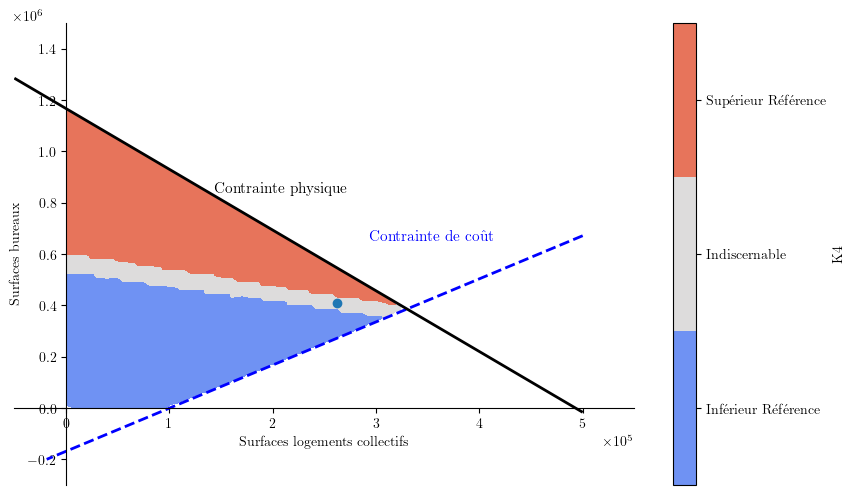

In [ ]:

short_name = dict(pl.read_excel('/home/thibault.chevilliet@enpc.fr/Documents/2607_acv_maquette/acv_from_maquette/short_indicateur.xlsx').iter_rows())
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": "Computer Modern",
})

x_annot_cout = 280000
y_annot_cout = 760000

x_annot_emp = 130000
y_annot_emp = 950000

N = 2000
x = np.linspace(-5E4, 5E5, N)
y = np.linspace(-2E5, 1.5E6, N)
X, Y = np.meshgrid(x, y)

cout = lambda x,y : cout_projet(x,y,param_amenageur)
emprise = lambda x,y : emprise_projet(x,y,param_amenageur)

mask = (
    (cout(X,Y) <= param_amenageur["subvention"])
    & (emprise(X,Y) <= param_amenageur["aire_projet"])
    & (X>=0) & (Y>=0)
    )


fig, ax = plt.subplots(figsize=(10, 6))


levels = np.linspace(np.min(z_data), np.max(z_data), 2)
# surf = ax.tricontourf(x_data,y_data ,z_data ,levels = [-1.5, -0.5, 0.5, 1.5],cmap='coolwarm',extend="both")
surf = ax.contourf(Xi,Yi ,Zi ,levels = [-1.5, -0.5, 0.5, 1.5],cmap='coolwarm')
# surf = ax.tripcolor(x_data,y_data ,z_data,shading='flat',cmap="coolwarm")
cbar = fig.colorbar(surf, ax=ax, label=index_comp)
cbar.set_ticks([-1,0,1])
cbar.set_ticklabels(["Inférieur Référence","Indiscernable","Supérieur Référence"])


# ax.scatter(x_data,y_data,c=z_data,cmap= "coolwarm")
# ax.scatter(x_data,y_data,marker="+",linewidths=0.5,color = "black")
# ax.scatter(X_valid,Y_valid,marker="+",linewidths=0.5,color = "black")
ax.scatter(x_ref,y_ref)


ax.contour(X, Y, cout_projet(X, Y, param_amenageur),
            levels=[param_amenageur["subvention"]], colors='blue', linewidths=2, linestyles='--')
ax.contour(X, Y, emprise_projet(X, Y, param_amenageur),
            levels=[param_amenageur["aire_projet"]], colors='black', linewidths=2, linestyles='-')


ax.annotate(f'Contrainte de coût',
            xy=(x_annot_cout, y_annot_cout), fontsize=11, color='blue',
            xytext=(10, -20), textcoords='offset points')


ax.annotate(f'Contrainte physique',
            xy=(x_annot_emp, y_annot_emp), fontsize=11, color='black',
            xytext=(10, -20), textcoords='offset points')


ax.set_xlabel('Surfaces logements collectifs')
ax.set_ylabel('Surfaces bureaux')

# ax.grid(True, alpha=0.2, color='white')


ax.set_xlim(-50000,550000)
ax.set_ylim(-300000,1500000)

ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')

ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-3, 3))
ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)

# ind_short = 
# plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Pb_amenageur/pb_amenageur_gwp_{index_comp}_dis_center.pdf",dpi=300,bbox_inches = "tight")
# plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Pb_amenageur/pb_amenageur_human_tox_{index_comp}_dis_lower_right.pdf",dpi=300,bbox_inches = "tight")
plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Pb_amenageur/pb_amenageur_ODP_{index_comp}_dis_lower_right.pdf",dpi=300,bbox_inches = "tight")
# plt.tight_layout()
# plt.show()

In [54]:
list(Y_valid)

[np.float64(0.0),
 np.float64(166666.66666666666),
 np.float64(166666.66666666666),
 np.float64(166666.66666666666),
 np.float64(166666.66666666666),
 np.float64(333333.3333333333),
 np.float64(333333.3333333333),
 np.float64(333333.3333333333),
 np.float64(333333.3333333333),
 np.float64(333333.3333333333),
 np.float64(333333.3333333333),
 np.float64(500000.0),
 np.float64(500000.0),
 np.float64(500000.0),
 np.float64(500000.0),
 np.float64(500000.0),
 np.float64(500000.0),
 np.float64(666666.6666666666),
 np.float64(666666.6666666666),
 np.float64(666666.6666666666),
 np.float64(666666.6666666666),
 np.float64(833333.3333333333),
 np.float64(833333.3333333333),
 np.float64(833333.3333333333),
 np.float64(1000000.0),
 np.float64(1000000.0),
 np.float64(1166666.6666666665)]

In [57]:
sorted(y_data)

[0.0,
 166666.66666666666,
 166666.66666666666,
 166666.66666666666,
 166666.66666666666,
 333333.3333333333,
 333333.3333333333,
 333333.3333333333,
 333333.3333333333,
 333333.3333333333,
 500000.0,
 500000.0,
 500000.0,
 500000.0,
 500000.0,
 500000.0,
 666666.6666666666,
 666666.6666666666,
 666666.6666666666,
 666666.6666666666,
 833333.3333333333,
 833333.3333333333,
 833333.3333333333,
 1000000.0,
 1000000.0,
 1166666.6666666665]